# Figure 3 (F1, C1, C2) of Keskar et al. (2017), _On large-batch training for deep learning_

Small-batch (256) and large-batch (10% of the training set) ADAM training for 100 epochs, then the loss and accuracy along $\alpha\,x_\ell^\star+(1-\alpha)\,x_s^\star$ for $\alpha\in[-1,2]$.
This notebook uses the saved runs in `results/`. Weights are excluded from Git; the JSON results include the measurements used in the report. Set `RUN_TRAINING = True` to regenerate the weights and interpolation with `run_all.sh` first.


In [1]:
import subprocess
import sys
from IPython.display import Image, display

RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run(["bash", "run_all.sh"], check=True)

## Figure 3

The required F1, C1 and C2 panels use batch-norm statistics recalibrated on the training set at each $\alpha$, with dropout disabled. The report also discusses a layer-normalization diagnostic.


saved figures/fig3_reproduced_bn-recompute.png


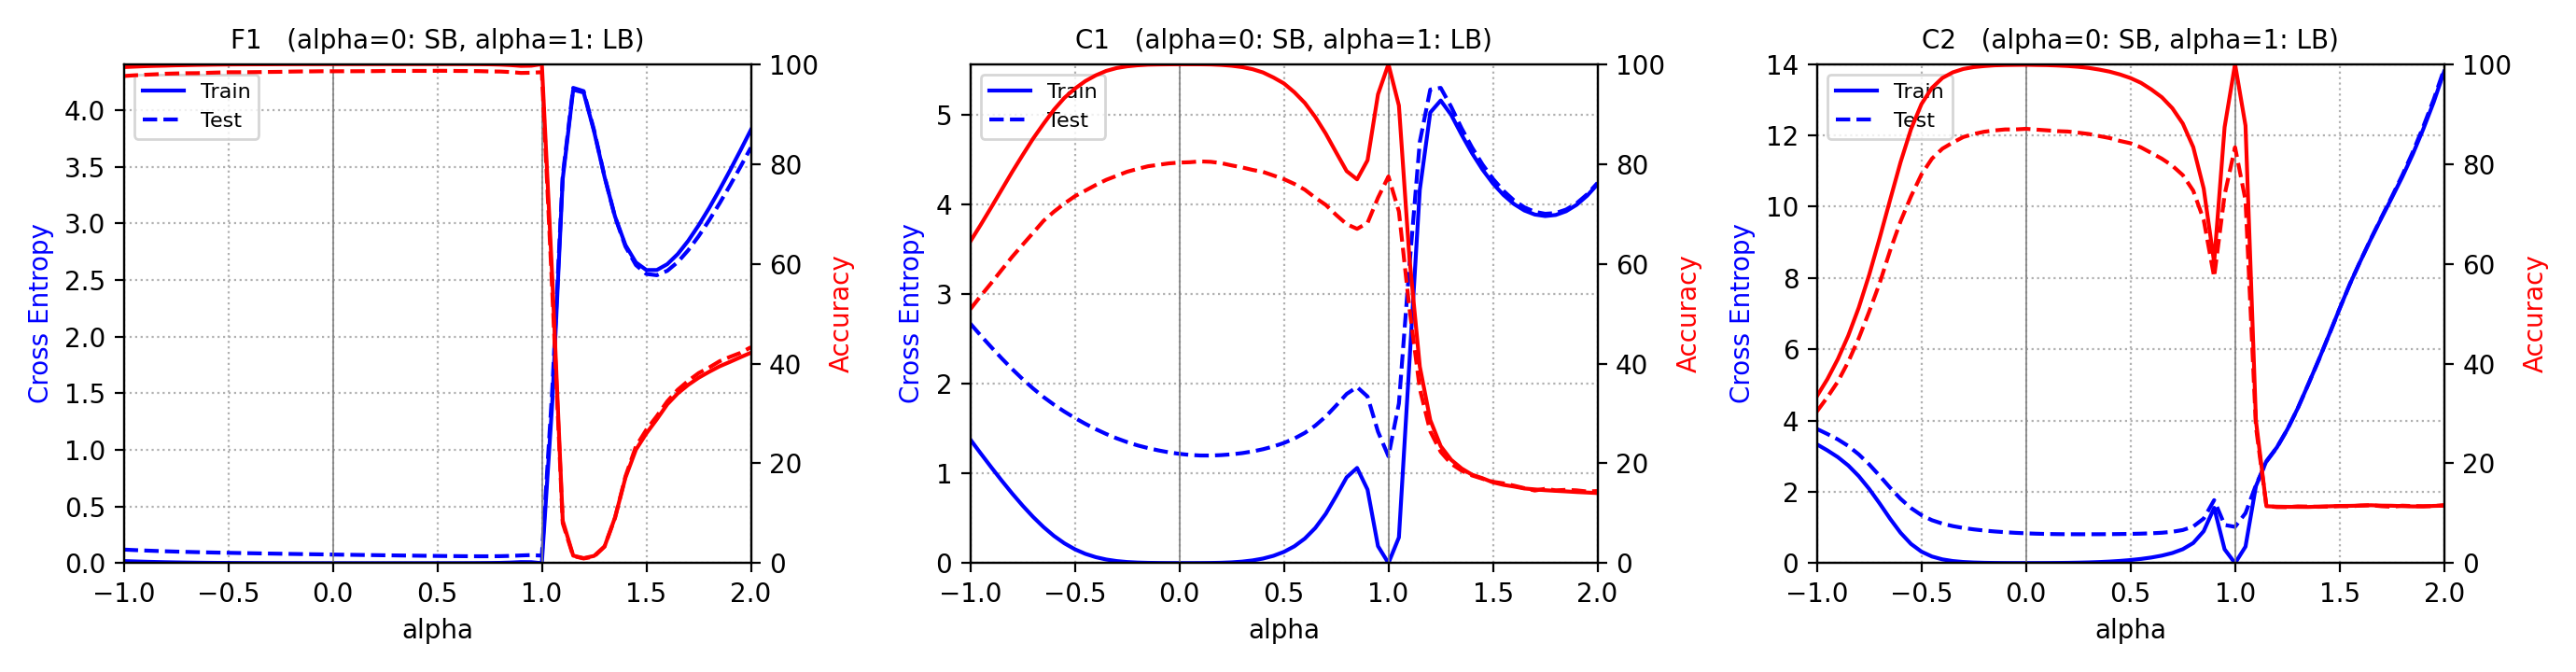

In [2]:
subprocess.run([sys.executable, "plot_fig3.py", "--bn", "recompute"], check=True)
display(Image("figures/fig3_reproduced_bn-recompute.png"))

## Numbers in the report

Final accuracies, distances from the starting point, layer norms and the loss along the line.


In [ ]:
subprocess.run(
    [sys.executable, "summarize.py", "--nets", "F1,C1,C2", "--seeds", "0"], check=True
)


=== F1 seed 0
  SB: batch   256, 100 epochs, train acc 100.00%  test acc 98.61%  train loss 0.00020  test loss 0.0762  best test acc 98.73%
  LB: batch  6000, 100 epochs, train acc 100.00%  test acc 98.41%  train loss 0.00002  test loss 0.0666  best test acc 98.42%
  test accuracy SB - LB = +0.20 points
  ||x_s - x0|| = 152.2   ||x_l - x0|| = 10.7   ratio = 14.27   ||x_s - x_l|| = 149.4
  ||x0|| = 58.5   ||x_s|| = 165.0   ||x_l|| = 59.7
  norm of each layer that is followed by batch norm (SB / LB): 80.3/14.2, 69.2/13.7, 68.0/13.7, 66.8/13.7, 65.9/13.7
  loss along the line, variant 'recompute':
    alpha     -1.00  -0.50  -0.25  +0.00  +0.25  +0.50  +0.75  +1.00  +1.25  +1.50  +2.00
    train loss 0.02   0.00   0.00   0.00   0.00   0.00   0.00   0.00   3.81   2.59   3.83
    test loss  0.12   0.09   0.08   0.08   0.07   0.06   0.06   0.07   3.82   2.55   3.67
    train acc 99.39  99.92  99.97  99.99  100.00  100.00  99.95  100.00   1.46  26.00  42.17
    test acc  97.61  98.37  98.45 

CompletedProcess(args=['/usr/local/bin/python3', 'summarize.py', '--nets', 'F1,C1,C2', '--seeds', '0'], returncode=0)

## Three seeds for F1


In [ ]:
subprocess.run(
    [sys.executable, "summarize.py", "--nets", "F1", "--seeds", "1,2"], check=True
)


=== F1 seed 1
  SB: batch   256, 100 epochs, train acc  99.98%  test acc 98.56%  train loss 0.00069  test loss 0.0759  best test acc 98.74%
  LB: batch  6000, 100 epochs, train acc 100.00%  test acc 98.41%  train loss 0.00002  test loss 0.0708  best test acc 98.43%
  test accuracy SB - LB = +0.15 points
  ||x_s - x0|| = 152.2   ||x_l - x0|| = 10.7   ratio = 14.26   ||x_s - x_l|| = 149.5
  ||x0|| = 58.4   ||x_s|| = 165.0   ||x_l|| = 59.7
  norm of each layer that is followed by batch norm (SB / LB): 80.3/14.2, 69.2/13.7, 68.2/13.7, 66.7/13.7, 65.8/13.7
  loss along the line, variant 'recompute':
    alpha     -1.00  -0.50  -0.25  +0.00  +0.25  +0.50  +0.75  +1.00  +1.25  +1.50  +2.00
    train loss 0.02   0.00   0.00   0.00   0.00   0.00   0.00   0.00   4.00   2.78   3.49
    test loss  0.12   0.09   0.08   0.08   0.07   0.07   0.06   0.07   4.03   2.78   3.38
    train acc 99.52  99.94  99.96  99.98  99.97  99.96  99.86  100.00   0.88  23.54  43.50
    test acc  97.70  98.46  98.53  9

CompletedProcess(args=['/usr/local/bin/python3', 'summarize.py', '--nets', 'F1', '--seeds', '1,2'], returncode=0)

## C1 as I first read it (stride-2 convolutions, `C1s2`)


In [ ]:
subprocess.run(
    [sys.executable, "summarize.py", "--nets", "C1s2", "--seeds", "0"], check=True
)


=== C1s2 seed 0
  SB: batch   256, 100 epochs, train acc  98.89%  test acc 69.18%  train loss 0.03231  test loss 2.0863  best test acc 71.76%
  LB: batch  5000, 100 epochs, train acc  96.29%  test acc 64.32%  train loss 0.10128  test loss 2.3303  best test acc 68.70%
  test accuracy SB - LB = +4.86 points
  ||x_s - x0|| = 74.8   ||x_l - x0|| = 21.4   ratio = 3.49   ||x_s - x_l|| = 72.4
  ||x0|| = 30.7   ||x_s|| = 80.4   ||x_l|| = 36.3
  norm of each layer that is followed by batch norm (SB / LB): 10.3/4.9, 43.9/9.3, 43.6/14.4, 38.5/10.6
  loss along the line, variant 'recompute':
    alpha     -1.00  -0.50  -0.25  +0.00  +0.25  +0.50  +0.75  +1.00  +1.25  +1.50  +2.00
    train loss 0.41   0.08   0.03   0.02   0.04   0.25   1.20   0.02   6.40   5.61   5.72
    test loss  2.43   2.26   2.19   2.11   2.04   2.08   2.47   2.19   6.83   5.58   5.73
    train acc 87.34  97.29  99.03  99.53  98.71  92.31  75.47  99.42  24.73  13.03  10.82
    test acc  63.16  67.56  69.09  69.77  69.97  68.

CompletedProcess(args=['/usr/local/bin/python3', 'summarize.py', '--nets', 'C1s2', '--seeds', '0'], returncode=0)